In [41]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# linear_model is a module in the scikit-learn library that provides various linear models for regression and classification tasks. The LinearRegression class is one of the most commonly used models for predicting a continuous target variable based on one or more input features. It fits a linear equation to the observed data and can be used to make predictions on new data points.

In [42]:
'''
syntax for linear regression is as follows:
from sklearn.linear_model import LinearRegression

sklearn -> package/tool
linear_model -> module(.py file)
LinearRegression -> class(from linear_model module) module

#model creation
model_lr = LinearRegression()

#modeltraining
fit()
what is fit()?
-it learns the pattern from the data(input and output) and stores the learned pattern in the model_lr object.

model_lr.fit(xtrain,ytrain)
#it uses OLS(Ordinary Least Squares) method to find the best fit line.

#finds the best fit line(mx+c)
-finds slope(m--->output) and intercept(c) of the best fit line using the training data.

'''


'\nsyntax for linear regression is as follows:\nfrom sklearn.linear_model import LinearRegression\n\nsklearn -> package/tool\nlinear_model -> module(.py file)\nLinearRegression -> class(from linear_model module) module\n\n#model creation\nmodel_lr = LinearRegression()\n\n#modeltraining\nfit()\nwhat is fit()?\n-it learns the pattern from the data(input and output) and stores the learned pattern in the model_lr object.\n\nmodel_lr.fit(xtrain,ytrain)\n#it uses OLS(Ordinary Least Squares) method to find the best fit line.\n\n#finds the best fit line(mx+c)\n-finds slope(m--->output) and intercept(c) of the best fit line using the training data.\n\n'

In [43]:
df=pd.read_csv('Ice_cream selling data.csv')

In [44]:
df.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [45]:
df.corr()

,Temperature (°C),Ice Cream Sales (units)
Temperature (°C),1.000000,-0.175184
Ice Cream Sales (units),-0.175184,1.000000


weakly corelated bcz its near to zero

In [46]:
x=df[['Temperature (°C)']]
y=df['Ice Cream Sales (units)']

In [47]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=42)

In [48]:
xtest

,Temperature (°C)
13,-1.818938
45,3.704057
47,4.133534
44,3.610778
17,-0.773330
27,1.024181
26,0.874905
25,0.693599
31,1.850552
19,-0.149635


In [49]:
model_lr=LinearRegression()

In [50]:
model_lr.fit(xtrain,ytrain)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [51]:
model_lr.intercept_

np.float64(17.1392131277583)

In [52]:
model_lr.coef_

array([-1.14658686])

In [53]:
'''
what is intercept_ and coef_?
intercept_ -> it is the value of c in the best fit line equation(mx+c)
coef_ -> it is the value of m in the best fit line equation(mx+c)


what is weights in linear regression?
-it tells the importance of the features(inputs)
-based on weights model decides the importance of features and predicts the output accordingly.
'''

'\nwhat is intercept_ and coef_?\nintercept_ -> it is the value of c in the best fit line equation(mx+c)\ncoef_ -> it is the value of m in the best fit line equation(mx+c)\n\n\nwhat is weights in linear regression?\n-it tells the importance of the features(inputs)\n-based on weights model decides the importance of features and predicts the output accordingly.\n'

### Actual data vs model predicted data :

In [54]:
ytrain_predicted=model_lr.predict(xtrain)

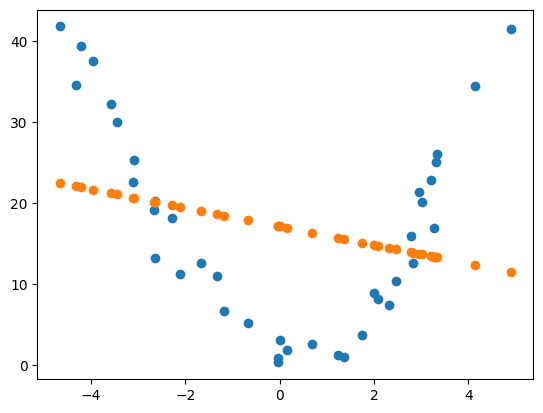

In [55]:
plt.scatter(xtrain,ytrain)  # actual inputs vs outputs
plt.scatter(xtrain,ytrain_predicted)  # actual inputs vs predicted outputs

Conclusion: 

Model is not able to capture the patterns 

Reason: 

The data is non-linear and linear regression can capture only linear data

( i.e., predicted data does not follow actual data, so this is non linear data)

In [56]:
'''
Why we're comparing actual outputs with predicted outputs?
1) plt.scatter(xtrain,ytrain)
2) plt.scatter(xtrain,ytrain_predicted)

Answer:
- from this comparison between actual and predicted outputs, 
  we can check how well the model has learned the pattern from the training data.
  
'''

"\nWhy we're comparing actual outputs with predicted outputs?\n1) plt.scatter(xtrain,ytrain)\n2) plt.scatter(xtrain,ytrain_predicted)\n\nAnswer:\n- from this comparison between actual and predicted outputs, \n  we can check how well the model has learned the pattern from the training data.\n  \n"

In [57]:
ytest_predicted=model_lr.predict(xtest)

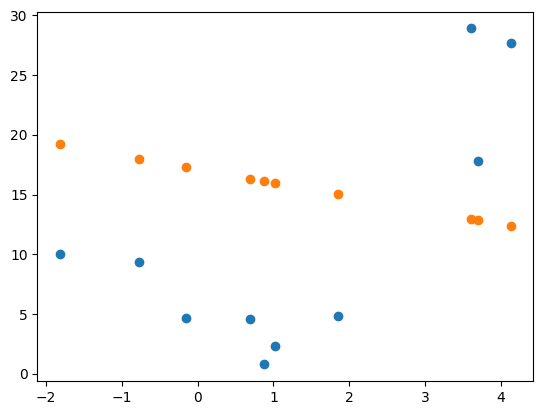

In [58]:
plt.scatter(xtest,ytest)  # actual inputs vs outputs
plt.scatter(xtest,ytest_predicted)  # actual inputs vs predicted outputs

Conclusion:

Model is unable capture the pattern from unseen data(test data)

Reason:

The data is non-linear and linear regression can capture only linear data, hence it can't predict the future

In [60]:
train_data=pd.DataFrame({
    'Xtrain':xtrain['Temperature (°C)'],
    'Ytrain':ytrain,
    'Ytrain_Predicted':ytrain_predicted
    })
train_data['Error']=train_data['Ytrain']-train_data['Ytrain_Predicted']

In [61]:
train_data

,Xtrain,Ytrain,Ytrain_Predicted,Error
12,-2.111870,11.218294,19.560655,-8.342361
4,-3.578554,32.284531,21.242336,11.042195
34,2.318591,7.412094,14.480747,-7.068653
8,-2.672461,19.226970,20.203422,-0.976452
3,-3.949661,37.539845,21.667843,15.872002
6,-3.108440,22.635401,20.703310,1.932092
40,3.211366,22.839406,13.457103,9.382303
41,3.270044,16.983279,13.389824,3.593455
46,4.130868,34.530743,12.402814,22.127929
15,-1.326379,10.957731,18.660022,-7.702291
